# Pesquisa: a biblioteca `qrcode`

**Autor:** Tomás Miguel · 12ºPI · UFCD 10793 Fundamentos de Python · Aula 28

Neste notebook estudo a biblioteca `qrcode`, que serve para gerar QR codes com Python.

**Índice**
1. O que é e para que serve
2. Como se instala
3. Quando se usa
4. Exemplos de código
5. Comparação com o `segno`
6. Fontes

## 1. O que é e para que serve

Um **QR code** é um código de barras a duas dimensões: um quadrado cheio de pontos pretos e brancos que guarda um texto (por exemplo, o endereço de um site). A câmara do telemóvel lê o desenho e mostra o texto.

A biblioteca **`qrcode`** faz o caminho inverso: recebe um texto em Python e devolve uma **imagem** com o QR code desse texto. Consegue gravar a imagem em PNG e também em SVG (imagem vetorial, que não perde qualidade ao ampliar).

## 2. Como se instala

A `qrcode` não vem com o Python (não faz parte da biblioteca padrão), por isso instala-se com o **pip**, que vai buscar o pacote ao **PyPI**.

- No terminal: `python -m pip install "qrcode[pil]"`
- No notebook: `%pip install "qrcode[pil]"` (o `%` serve para correr o pip dentro do notebook)

O `[pil]` pede também a instalação do **Pillow**, a biblioteca que desenha e grava as imagens. Sem ele, só há opções mais limitadas de gerar imagens.

Se a célula terminar a dizer que podes precisar de reiniciar o kernel, clica em **Restart** na barra do notebook antes de continuar.

In [1]:
%pip install "qrcode[pil]"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Para **confirmar** que ficou instalado, o `pip show` mostra o nome, a versão e um resumo do pacote:

In [2]:
%pip show qrcode

Name: qrcode
Version: 8.2
Summary: QR Code image generator
Home-page: https://github.com/lincolnloop/python-qrcode
Author: Lincoln Loop
Author-email: info@lincolnloop.com
License: BSD
Location: c:\Users\PC\Desktop\LP 12º Ano\.venv\Lib\site-packages
Requires: colorama
Required-by: 
Note: you may need to restart the kernel to use updated packages.


## 3. Quando se usa

**Faz sentido usar** quando queres criar QR codes por programa, sem ir a um site:
- um QR code com o link do teu projeto no GitHub, para pôr num cartaz ou num trabalho;
- vários QR codes de uma vez a partir de uma lista (por exemplo, um por produto ou por aluno);
- ligar a geração de QR codes a outro programa teu.

**Não vale a pena** se só precisas de um QR code uma vez: é mais rápido usar um gerador online.

## 4. Exemplos de código

### Exemplo 1: o QR code mais simples

- `import qrcode` traz a biblioteca para o programa.
- `qrcode.make("texto")` recebe o texto e devolve a imagem do QR code.
- `img.save("nome.png")` grava a imagem num ficheiro.
- `Image("nome.png")` (do `IPython.display`) mostra o ficheiro aqui no notebook, para o resultado ficar visível.

**Resultado esperado:** aparece um QR code. Experimenta lê-lo com a câmara do telemóvel: deve abrir o link.

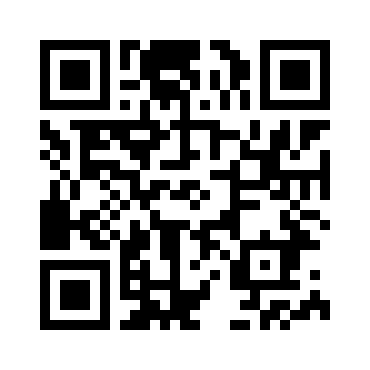

In [3]:
import qrcode
from IPython.display import Image

img = qrcode.make("https://github.com/Tomasmmiguel")
img.save("qr_github.png")
Image("qr_github.png")

### Exemplo 2: com opções (tamanho, cores e correção de erros)

Aqui usa-se a **classe `QRCode`**, que dá mais controlo. Os parâmetros:

- `version` — o tamanho do desenho (de 1 a 40). Com `fit=True`, a biblioteca escolhe sozinha a versão mais pequena em que o texto cabe.
- `error_correction` — quanto do QR code pode estar riscado ou tapado e continuar a ler-se. Há quatro níveis: `ERROR_CORRECT_L` (o mais baixo, cerca de 7%), `M` (o valor por omissão), `Q` e `H` (o mais alto). Mais correção = desenho mais denso.
- `box_size` — quantos pixels tem cada quadradinho.
- `border` — a margem à volta, medida em quadradinhos.

Depois: `add_data` põe o texto, `make(fit=True)` calcula o desenho, e `make_image` cria a imagem com as cores que escolheres.

**Resultado esperado:** um QR code azul-escuro sobre fundo branco, e uma linha a dizer que versão foi usada.

Versão usada: 2


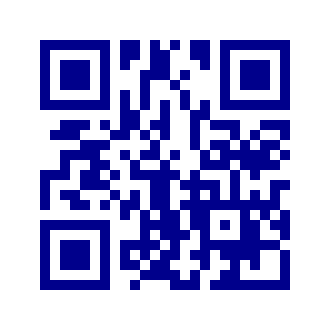

In [4]:
qr = qrcode.QRCode(
    version=1,
    error_correction=qrcode.constants.ERROR_CORRECT_H,
    box_size=10,
    border=4,
)

qr.add_data("Olá, mundo!")
qr.make(fit=True)
print("Versão usada:", qr.version)

img = qr.make_image(fill_color="darkblue", back_color="white")
img.save("qr_opcoes.png")
Image("qr_opcoes.png")

### Exemplo 3: vários QR codes com um ciclo `for`

Tenho um dicionário com nomes e links. O ciclo percorre-o com `.items()` (que dá o par nome/link de cada vez) e cria um ficheiro por QR code. Os nomes dos ficheiros são feitos com uma f-string: `f"qr_{nome}.png"`.

**Resultado esperado:** três linhas "Criado: ..." e, depois, a imagem de um dos QR codes.

Aqui está a vantagem real da biblioteca: com mais links na lista, o código não muda.

Criado: qr_github.png
Criado: qr_python.png
Criado: qr_pypi.png


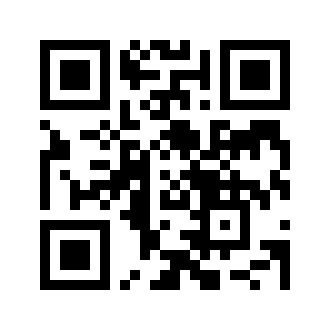

In [5]:
links = {
    "github": "https://github.com",
    "python": "https://www.python.org",
    "pypi": "https://pypi.org",
}

for nome, url in links.items():
    qrcode.make(url).save(f"qr_{nome}.png")
    print("Criado:", f"qr_{nome}.png")

Image("qr_python.png")

## 5. Comparação com o `segno`

O **`segno`** é outra biblioteca de Python que também gera QR codes. Vou fazer o mesmo QR code com as duas e comparar.

Instala-se com o pip, como a `qrcode`:

In [6]:
%pip install segno

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Primeiro, o mesmo texto com as duas bibliotecas. A seguir comparo o resultado com `os.path.getsize`, que diz o tamanho de cada ficheiro em bytes.

> ⚠️ A sintaxe do `segno` (`segno.make` e `.save(..., scale=...)`) deve ser confirmada na documentação dele antes de entregar. Se der erro, o que está na documentação oficial é o que manda.

cmp_qrcode.png 783 bytes
cmp_segno.png 395 bytes


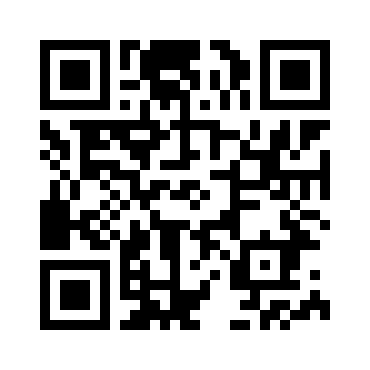

In [7]:
import os
import qrcode
import segno
from IPython.display import Image

texto = "https://github.com/Tomasmmiguel"

# com a qrcode
qrcode.make(texto).save("cmp_qrcode.png")

# com o segno
segno.make(texto).save("cmp_segno.png", scale=10)

for ficheiro in ("cmp_qrcode.png", "cmp_segno.png"):
    print(ficheiro, os.path.getsize(ficheiro), "bytes")

Image("cmp_qrcode.png")

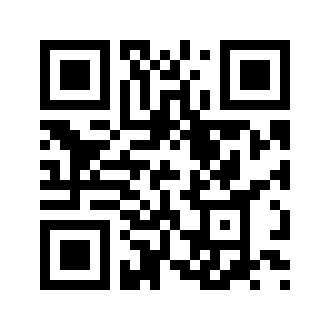

In [8]:
Image("cmp_segno.png")

### Quadro comparativo

| | `qrcode` | `segno` |
|---|---|---|
| Como se instala | `pip install "qrcode[pil]"` | `pip install segno` |
| Precisa do Pillow para imagens? | Não é obrigatório: a instalação simples gera PNG sozinha. O `[pil]` junta o Pillow para ter mais opções de imagem. | Não. Não tem dependências. |
| Formatos de saída | PNG e SVG, e imagens com estilos (cantos redondos, gradientes) quando usa o Pillow | SVG, PNG, PDF, EPS e outros, e texto no terminal |
| Facilidade de uso | `qrcode.make(texto).save("x.png")`: uma linha, depois do `import` | `segno.make(texto).save("x.png")`: uma linha, depois do `import` |
| Outras diferenças que encontrei | Tem imagens com estilos, usando o Pillow | Gera também Micro QR Codes e tem funções para QR codes de contacto e de Wi-Fi |

**Conclusão:** Para um QR code simples as duas fazem o mesmo e com o mesmo esforço. Usava a `qrcode` se quisesse imagens com estilos (cores e formas diferentes), e o `segno` se precisasse de outros formatos (por exemplo PDF), de Micro QR Codes ou de uma biblioteca sem dependências.

## 6. Fontes

- `qrcode` no PyPI: https://pypi.org/project/qrcode/
- Repositório oficial da `qrcode` no GitHub: https://github.com/lincolnloop/python-qrcode
- `segno` no PyPI: https://pypi.org/project/segno/
- Documentação do `segno`: https://segno.readthedocs.io/
- Instalação de pacotes com o pip: https://docs.python.org/3/installing/index.html

*(Abre cada endereço antes de entregar e confirma que funciona. Apaga os que não usaste.)*